

- Authorship: Noah Ring
- Year: 2026
- Program: EarthRISE Developers Academy
- Location: Langley Research Center

# Initialize Notebook

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import numpy as np
import cartopy
import seaborn as sns

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

# EPSG to be used when setting coordinate reference systems
epsg = 4326 

# Function used for coercing clarity lat/lon to match the 0.2 x 0.2deg grid of TEMPO
# Note: I included the bias term (0.01) to force the lat/lon to match TEMPO lat/lon
def round_002(x):
    out = 0.02*np.floor(x/0.02) + 0.01
    return np.round(out, 2)

def windSpd(u, v):
    out = np.sqrt(u**2 + v**2)
    return out

def windDir(u, v):
    phi = 180 + (180/np.pi)*np.atan2(v,u)
    return phi

def distance(lat1,lat2,lon1,lon2):
    dist = np.sqrt((lat2-lat1)**2 + (lon2-lon1)**2)
    return dist

def round_002_vectorized(arr):
    return xr.apply_ufunc(round_002, arr, vectorize=True)

write_files = True 


# Functions 

In [2]:
def get_corners(input_array):
     # Define the maximum and minimum dimensions of the input data to get the extent of interest:
    min_lat = (
        input_array.latitude.values.min() - 1 # 0.25
    )  # get the minimum latitude from the input dataset, subtract 0.25 for a buffer
    max_lat = (
        input_array.latitude.values.max() + 1 # 0.25
    )  # get the maximum latitude from the input dataset, add 0.25 for a buffer
    min_lon = (
        input_array.longitude.values.min() - 1 # 0.25
    )  # get the minimum longitude from the input dataset, subtract 0.25 for a buffer
    max_lon = (
        input_array.longitude.values.max() + 1 # 0.25 
    )  # get the maximum longitude from the input dataset, add 0.25 for a buffer
    # min_time = input_array.datetime.values.min() - np.timedelta64(
    #     1, "h"
    # )  # get the minimum time from the input dataset, subtract 1 hour for a buffer
    # max_time = input_array.datetime.values.max() + np.timedelta64(
    #     1, "h"
    # )  # get the maximum time from the input dataset, add 1 hour for a buffer 
    return min_lat, max_lat, min_lon, max_lon 


def resample_merra2_to_tempo(input_array, merra_path, interp = "nearest"):
    #this function was repurposed and edited from:
    # https://github.com/nasa/ASDC_Data_and_User_Services/blob/main/TEMPO/D2P5_exercise_surface_level_AQ_complete.ipynb

    # if isinstance(input_array, xr.Dataset):
    #     try:
    #         input_array = xr.Dataset({input_array.name: input_array})
    #     except Exception:
    #         print("ERROR: input data type can not be converted to a dataset.")

    # Define the maximum and minimum dimensions of the input data to get the extent of interest:
    min_lat = (
        input_array.latitude.values.min() - 1 # 0.25
    )  # get the minimum latitude from the input dataset, subtract 0.25 for a buffer
    max_lat = (
        input_array.latitude.values.max() + 1 # 0.25
    )  # get the maximum latitude from the input dataset, add 0.25 for a buffer
    min_lon = (
        input_array.longitude.values.min() - 1 # 0.25
    )  # get the minimum longitude from the input dataset, subtract 0.25 for a buffer
    max_lon = (
        input_array.longitude.values.max() + 1 # 0.25 
    )  # get the maximum longitude from the input dataset, add 0.25 for a buffer
    min_time = input_array.datetime.values.min() - np.timedelta64(
        1, "h"
    )  # get the minimum time from the input dataset, subtract 1 hour for a buffer
    max_time = input_array.datetime.values.max() + np.timedelta64(
        1, "h"
    )  # get the maximum time from the input dataset, add 1 hour for a buffer

    merra_slice_u_2m = xr.open_dataset(merra_path).loc[
        {
            "time": slice(min_time, max_time),
            "lat": slice(min_lat, max_lat),
            "lon": slice(min_lon, max_lon),
        }
    ]["U2M"]  # access column NO2 data for the time and location
    merra_slice_v_2m = xr.open_dataset(merra_path).loc[
        {
            "time": slice(min_time, max_time),
            "lat": slice(min_lat, max_lat),
            "lon": slice(min_lon, max_lon),
        }
    ]["V2M"]  # access column NO2 data for the time and location
    merra_slice_u_10m = xr.open_dataset(merra_path).loc[
        {
            "time": slice(min_time, max_time),
            "lat": slice(min_lat, max_lat),
            "lon": slice(min_lon, max_lon),
        }
    ]["U10M"]  # access column NO2 data for the time and location
    merra_slice_v_10m = xr.open_dataset(merra_path).loc[
        {
            "time": slice(min_time, max_time),
            "lat": slice(min_lat, max_lat),
            "lon": slice(min_lon, max_lon),
        }
    ]["V10M"]  # access column NO2 data for the time and location


    merra_rename_u_2m = merra_slice_u_2m.rename(
        {"lat": "latitude", "lon": "longitude", "time":"datetime"}
    )  # rename the data dimensions to match the input file dimensions
    merra_rename_v_2m = merra_slice_v_2m.rename(
        {"lat": "latitude", "lon": "longitude", "time":"datetime"}
    )  # rename the data dimensions to match the input file dimensions
    merra_rename_u_10m = merra_slice_u_10m.rename(
        {"lat": "latitude", "lon": "longitude", "time":"datetime"}
    )  # rename the data dimensions to match the input file dimensions
    merra_rename_v_10m = merra_slice_v_10m.rename(
        {"lat": "latitude", "lon": "longitude", "time":"datetime"}
    )  # rename the data dimensions to match the input file dimensions

    merra_interp_u_2m = merra_rename_u_2m.interp_like(
        input_array, method=interp
    )  # interpolate the GEOS-CF grid to the input dataset grid
    merra_interp_v_2m = merra_rename_v_2m.interp_like(
        input_array, method=interp
    )  # interpolate the GEOS-CF grid to the input dataset grid
    merra_interp_u_10m = merra_rename_u_10m.interp_like(
        input_array, method=interp
    )  # interpolate the GEOS-CF grid to the input dataset grid
    merra_interp_v_10m = merra_rename_v_10m.interp_like(
        input_array, method=interp
    )  # interpolate the GEOS-CF grid to the input dataset grid

    # Add the data into the output:
    output_array = input_array
    output_array["U2M"] = merra_interp_u_2m
    output_array["V2M"] = merra_interp_v_2m
    output_array["U10M"] = merra_interp_u_10m
    output_array["V10M"] = merra_interp_v_10m

    # Return the GEOS-CF Data as well:
    merra_wind = xr.merge([merra_interp_u_2m, merra_interp_v_2m, merra_interp_u_10m, merra_interp_v_10m])

    # Return the outputs:
    return output_array, merra_wind 


def F_plot_map(a_data_plot=None,
               a_data_plot_point=None,
               n_lat_min=-90,
               n_lat_max=90,
               n_lon_min=-180,
               n_lon_max=180,
               my_cmap = plt.get_cmap('Oranges'),
               Colorbar_Label = None,
               Plot_Title = None,
               Colorbar_Limits = [0,1],
               n_pointsize = 20,
               n_latlon_gridspacing = 1,
               o_figure = None,
               o_axis = None,
               o_plot = None,
               SHOW=True,
               b_shapefiles=True):
  '''
  This function creates a map plot from gridded or point data.
  Inputs:
    a_data_plot: gridded data (in xarray format) to plot on the map.
    a_data_plot_point: point data (in pandas table format) to plot on the map.
    n_lat_min: minimum latitude of the map.
    n_lat_max: maximum latitude of the map.
    n_lon_min: minimum longitude of the map.
    n_lon_max: maximum longitude of the map.
    my_cmap: color scale to be used by the plot.
    Colorbar_Label: label for the color scale.
    Plot_Title: title for the plot.
    Colorbar_Limits: limits for the color scale.
    n_pointsize: point size for the point data.
    n_latlon_gridspacing: spacing between latitude and longitude gridlines on the map
    o_figure: figure object to use for the plot.
    o_axis: axis object to use for the plot.
    o_plot: plot object to use for the plot.
    SHOW: if True, the plot will be shown.
    b_shapefiles: if True, borders and coastlines will be included in the plot.
  Outputs:
    o_figure: figure object used for the plot.
    o_axis: axis object used for the plot.
    o_plot: plot object used for the plot.
  '''
  if o_figure is None:
    o_figure,o_axis = plt.subplots(1,1)
    o_axis.remove()
    o_axis = o_figure.add_subplot(1,1,1,projection=cartopy.crs.PlateCarree())
  if b_shapefiles:
    o_axis.coastlines()
    o_axis.add_feature(cartopy.feature.LAKES, edgecolor='black', facecolor='none', linestyle='-')
    o_axis.add_feature(cartopy.feature.BORDERS, edgecolor='black', facecolor='none', linestyle='--')
    o_axis.add_feature(cartopy.feature.STATES, edgecolor='black', facecolor='none', linestyle=':')
  o_axis.set_extent([np.max([n_lon_min-0.001,-180]), np.min([n_lon_max+0.001,180]), np.max([n_lat_min-0.001,-90]), np.min([n_lat_max+0.001,90])])
  gridlines = o_axis.gridlines(crs=cartopy.crs.PlateCarree(), xlocs=range(np.int_(np.floor(np.max([n_lon_min,-180]))),np.int_(np.ceil(np.min([n_lon_max,180])))+1,n_latlon_gridspacing), ylocs=range(np.int_(np.floor(np.max([n_lat_min,-90]))),np.int_(np.ceil(np.min([n_lat_max,90])))+1,n_latlon_gridspacing), draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')
  gridlines.top_labels = False
  gridlines.right_labels = False

  if a_data_plot is not None:
    if {'datetime','latitude','longitude'}.issubset(a_data_plot.dims):
      a_data_plot = a_data_plot.rename({'datetime':'time','latitude':'lat','longitude':'lon'})
    elif {'datetime','latitude','longitude'}.issubset(a_data_plot.coords):
      a_data_plot = a_data_plot.rename({'datetime':'time','latitude':'lat','longitude':'lon'})
    else:
      pass
    if 'time' in a_data_plot.dims:
      # take average for plotting:
      a_data_plot = a_data_plot.mean(dim='time')
  else:
    # Create a synthetic dataset to enable a colorbar:
    if Colorbar_Limits is None:
      a_data_plot = xr.DataArray([[Colorbar_Limits[0],Colorbar_Limits[0]],[Colorbar_Limits[1],Colorbar_Limits[1]]],dims=('lat','lon'),coords={'lat':[n_lat_max+1,n_lat_max+2],'lon':[n_lon_max+1,n_lon_max+2]})
    else:
      a_data_plot = xr.DataArray([[0,1],[2,3]],dims=('lat','lon'),coords={'lat':[n_lat_max+1,n_lat_max+2],'lon':[n_lon_max+1,n_lon_max+2]})
  if Colorbar_Limits is None:
    if Colorbar_Label is not None:
      o_plot = a_data_plot.plot(ax=o_axis,cmap=my_cmap,cbar_kwargs={'label': Colorbar_Label})
    else:
      o_plot = a_data_plot.plot(ax=o_axis,cmap=my_cmap)
  else:
    if Colorbar_Label is not None:
      o_plot = a_data_plot.plot(ax=o_axis,cmap=my_cmap,vmin=Colorbar_Limits[0],vmax=Colorbar_Limits[1],cbar_kwargs={'label': Colorbar_Label})
    else:
      o_plot = a_data_plot.plot(ax=o_axis,cmap=my_cmap,vmin=Colorbar_Limits[0],vmax=Colorbar_Limits[1])
  if a_data_plot_point is not None:
    if type(a_data_plot_point) is pd.Series:
        f_data_plot_point = a_data_plot_point
        if 'time' in f_data_plot_point.index.names:
            f_data_plot_point = f_data_plot_point.groupby(['lat','lon']).mean('time')
        v_lat_plot = f_data_plot_point.reset_index()['lat'].values
        v_lon_plot = f_data_plot_point.reset_index()['lon'].values
        v_data_temp = f_data_plot_point.values
    else:
        v_lat_plot = np.array(a_data_plot_point.lat)
        v_lon_plot = np.array(a_data_plot_point.lon)
        if 'time' in a_data_plot_point.dims:
          # take average for plotting:
          v_data_temp = np.array(a_data_plot_point.mean(dim='time'))
        else:
          v_data_temp = np.array(a_data_plot_point)
    if Colorbar_Limits is None:
      o_plot_point = o_axis.scatter(x=v_lon_plot,y=v_lat_plot,s=n_pointsize,edgecolors='k',c=v_data_temp,cmap=my_cmap)
    else:
      o_plot_point = o_axis.scatter(x=v_lon_plot,y=v_lat_plot,s=n_pointsize,edgecolors='k',c=v_data_temp,vmin=Colorbar_Limits[0],vmax=Colorbar_Limits[1],cmap=my_cmap)
  if Plot_Title is not None:
    o_axis.set_title(Plot_Title)
  if SHOW:
    o_figure.show()
  return o_figure,o_axis,o_plot


# Data Loading

## Load in TEMPO Data

In [3]:
#Define the path where the tempo files are stored.
tempo_path = "~/Documents/01_Research/larc-chicago-haq/datasets/tempo.nc"
tempo_addvar_path = "~/Documents/01_Research/larc-chicago-haq/datasets/tempo_addVar.nc"

# Use xarray to load tempo data
tempo_raster = xr.open_dataset(tempo_path)
tempo_raster = tempo_raster.rename({"vertical_column_troposphere":"column_no2"})
tempo_raster = tempo_raster.rename({"time": "datetime"})

tempo_addvar = xr.open_dataset(tempo_addvar_path)

tempo_pbl_rast = tempo_addvar.pbl_height
tempo_pbl_rast = tempo_pbl_rast.rename({"time": "datetime"})

tempo_solar_zenith = tempo_addvar.solar_zenith_angle
tempo_solar_zenith = tempo_solar_zenith.rename({"time": "datetime"})


tempo_raster = tempo_raster.assign_coords(
    latitude = round_002_vectorized(tempo_raster.latitude.astype('float64')),
    longitude = round_002_vectorized(tempo_raster.longitude.astype('float64'))
)
tempo_pbl_rast = tempo_pbl_rast.assign_coords(
    latitude = round_002_vectorized(tempo_pbl_rast.latitude.astype('float64')),
    longitude = round_002_vectorized(tempo_pbl_rast.longitude.astype('float64'))
)
tempo_solar_zenith = tempo_solar_zenith.assign_coords(
    latitude = round_002_vectorized(tempo_solar_zenith.latitude.astype('float64')),
    longitude = round_002_vectorized(tempo_solar_zenith.longitude.astype('float64'))
)

tempo_subset_rast = xr.merge([tempo_raster, tempo_pbl_rast, tempo_solar_zenith], join="outer", compat="no_conflicts")

tempo_subset_rast



<xarray.Dataset> Size: 244MB
Dimensions:                 (datetime: 3377, latitude: 58, longitude: 52)
Coordinates:
  * datetime                (datetime) datetime64[ns] 27kB 2025-09-04T11:47:2...
  * latitude                (latitude) float64 464B 41.27 41.29 ... 42.39 42.41
  * longitude               (longitude) float64 416B -88.25 -88.23 ... -87.23
Data variables:
    column_no2              (datetime, latitude, longitude) float64 81MB ...
    main_data_quality_flag  (datetime, latitude, longitude) float32 41MB ...
    eff_cloud_fraction      (datetime, latitude, longitude) float32 41MB ...
    pbl_height              (datetime, latitude, longitude) float32 41MB ...
    solar_zenith_angle      (datetime, latitude, longitude) float32 41MB ...
Attributes:
    long_name:  troposphere nitrogen dioxide vertical column
    units:      molecules/cm^2

## MERRA2

In [4]:
# Path for MERRA2
merra_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/merra2_subset.nc"

tempo_merra, merra_wind = resample_merra2_to_tempo(tempo_subset_rast, merra_path)

tempo_merra = tempo_merra.assign_coords(
    latitude = round_002_vectorized(tempo_merra.latitude.astype('float64')),
    longitude = round_002_vectorized(tempo_merra.longitude.astype('float64'))
)

# tempo_merra['windspeed_2m'] = windSpd(tempo_merra['U2M'], tempo_merra['V2M']) 
# tempo_merra['winddir_2m'] = windDir(tempo_merra['U2M'], tempo_merra['V2M']) 

# tempo_merra['windspeed_10m'] = windSpd(tempo_merra['U10M'], tempo_merra['V10M']) 
# tempo_merra['winddir_10m'] = windDir(tempo_merra['U10M'], tempo_merra['V10M']) 

tm_subset = tempo_merra.to_dataframe().reset_index()
tm_subset['hour'] = tm_subset['datetime'].dt.hour
tm_subset['doy'] = tm_subset['datetime'].dt.dayofyear
tm_subset['month'] = tm_subset['datetime'].dt.month
tm_subset['week'] = tm_subset['datetime'].dt.isocalendar().week
tm_subset["year"] = tm_subset['datetime'].dt.year
tm_subset["datetime"] = (
    pd.to_datetime(tm_subset["datetime"], errors="coerce")
    .dt.floor("s")
)


In [12]:
tm_subset

,datetime,latitude,longitude,column_no2,main_data_quality_flag,eff_cloud_fraction,pbl_height,solar_zenith_angle,U2M,V2M,...,V10M,windspeed_2m,winddir_2m,windspeed_10m,winddir_10m,hour,doy,month,week,year
0,2025-09-04 11:47:23,41.27,-88.25,NaN,NaN,NaN,223.0,81.413406,1.248071,-1.996782,...,-3.029129,2.354744,122.00708,3.570464,121.963531,11,247,9,36,2025
1,2025-09-04 11:47:23,41.27,-88.23,NaN,NaN,NaN,223.0,81.403412,1.248071,-1.996782,...,-3.029129,2.354744,122.00708,3.570464,121.963531,11,247,9,36,2025
2,2025-09-04 11:47:23,41.27,-88.21,NaN,NaN,NaN,223.0,81.379692,1.248071,-1.996782,...,-3.029129,2.354744,122.00708,3.570464,121.963531,11,247,9,36,2025
3,2025-09-04 11:47:23,41.27,-88.19,NaN,NaN,NaN,223.0,81.379700,1.248071,-1.996782,...,-3.029129,2.354744,122.00708,3.570464,121.963531,11,247,9,36,2025
4,2025-09-04 11:47:23,41.27,-88.17,NaN,NaN,NaN,223.0,81.366753,1.248071,-1.996782,...,-3.029129,2.354744,122.00708,3.570464,121.963531,11,247,9,36,2025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10185027,2026-06-01 23:46:54,42.41,-87.31,1.764054e+14,0.0,0.025435,862.0,76.168282,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,23,152,6,23,2026
10185028,2026-06-01 23:46:54,42.41,-87.29,1.867609e+14,0.0,0.025017,863.0,76.168327,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,23,152,6,23,2026
10185029,2026-06-01 23:46:54,42.41,-87.27,5.162343e+14,0.0,0.031638,863.0,76.178139,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,23,152,6,23,2026
10185030,2026-06-01 23:46:54,42.41,-87.25,1.298819e+15,0.0,0.047531,863.0,76.201439,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,23,152,6,23,2026


## CLARITY

In [5]:

# Define the path where the open air chicago clarity data is stored
clarity_path = "~/Documents/01_Research/larc-chicago-haq/datasets/Open_Air_Chicago_Individual_Measurements_20260615.csv"

# Load clarity data .csv
clarity_full_dat = pd.read_csv(clarity_path)

# Subset the clarity sensor data for our variables of interest
# Reformat the datetime variable, and add other time columns to possibly be used later
clarity_subset = clarity_full_dat[['datasourceid', 'sensor_name', 'latitude', 'longitude', 'time',
                            'no2ConcIndividual.value']]
clarity_subset['datetime'] = (
    pd.to_datetime(clarity_subset["time"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    .dt.floor("s")
)
clarity_subset = clarity_subset.drop('time', axis=1)
clarity_subset['doy'] = clarity_subset['datetime'].dt.dayofyear
clarity_subset['hour'] = clarity_subset['datetime'].dt.hour
clarity_subset["year"] = clarity_subset['datetime'].dt.year
clarity_subset["week"] = clarity_subset['datetime'].dt.isocalendar().week
clarity_subset['month'] = clarity_subset['datetime'].dt.month
clarity_subset['latitude'] = round_002(clarity_subset['latitude'].astype('float64'))
clarity_subset['longitude'] = round_002(clarity_subset['longitude'].astype('float64'))


sensors_per_pixel = (
    clarity_subset.groupby(['latitude','longitude'])
    .agg(sensor_count=('datasourceid', 'nunique'))
    )


clarity_subset = clarity_subset.merge(sensors_per_pixel, how='left', on=['latitude','longitude'])
clarity_subset


,datasourceid,sensor_name,latitude,longitude,no2ConcIndividual.value,datetime,doy,hour,year,week,month,sensor_count
0,DUUZN2841,Logan Square 3,41.93,-87.69,NaN,2026-01-18 13:14:59,18,13,2026,3,1,2
1,DGKDK3415,Irving Park 4,41.95,-87.73,NaN,2026-01-18 12:24:16,18,12,2026,3,1,2
2,DQUUS8611,West Town 4,41.89,-87.67,17.55,2026-06-10 23:05:39,161,23,2026,24,6,1
3,DFAQM2360,Englewood 1,41.79,-87.65,9.21,2026-03-27 09:36:07,86,9,2026,13,3,1
4,DCRJT8545,Greater Grand Crossing 6,41.75,-87.63,8.69,2026-04-28 07:23:59,118,7,2026,18,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...
8168103,DYZXT2661,Washington Park 1,41.79,-87.61,31.89,2026-03-06 22:23:46,65,22,2026,10,3,3
8168104,DBASA0396,Washington HS Collocation 1,41.69,-87.53,NaN,2026-02-23 21:50:42,54,21,2026,9,2,4
8168105,DPMHQ8304,Uptown 1,41.97,-87.67,10.37,2026-04-28 22:11:46,118,22,2026,18,4,2
8168106,DYZXT2661,Washington Park 1,41.79,-87.61,10.61,2026-05-10 17:44:11,130,17,2026,19,5,3


In [9]:
tm_dat = tm_subset 
clarity_dat = clarity_subset

start_date = tm_subset['datetime'].min()
end_date = tm_subset['datetime'].max()

cd_subset = clarity_dat[['year', 'month','week', 'doy', 'hour', 'datetime', 'latitude', 'longitude', 'no2ConcIndividual.value']]

tempo_no2 = tm_dat[['column_no2','pbl_height','solar_zenith_angle',
                            'U2M', 'V2M', 'U10M', 'V10M',
                           'datetime','latitude','longitude',
                           'year','month','week','doy','hour']]

combined = cd_subset.merge(tempo_no2, 
                            on=['datetime', 'year', 'month','week', 'doy', 'hour', 'latitude','longitude'],
                            how='outer',
                            validate='many_to_many')

combined = combined.reset_index().drop('index',axis=1)
combined = combined.drop_duplicates()
combined['sfc_no2'] = combined['no2ConcIndividual.value']
combined = combined.drop('no2ConcIndividual.value', axis=1)

if write_files == True:
    output_path = "~/Documents/01_Research/larc-chicago-haq/datasets/fulldat-unaggregated.csv"
    combined.to_csv(output_path)


combined 

,year,month,week,doy,hour,datetime,latitude,longitude,column_no2,pbl_height,solar_zenith_angle,U2M,V2M,U10M,V10M,sfc_no2
0,2025,9,36,244,0,2025-09-01 00:00:05,41.71,-87.69,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.90
1,2025,9,36,244,0,2025-09-01 00:00:11,41.91,-87.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.16
2,2025,9,36,244,0,2025-09-01 00:00:21,41.67,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.46
3,2025,9,36,244,0,2025-09-01 00:00:28,41.93,-87.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.98
4,2025,9,36,244,0,2025-09-01 00:00:32,41.71,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18352082,2026,6,25,166,0,2026-06-15 00:02:10,41.97,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.08
18352083,2026,6,25,166,0,2026-06-15 00:02:12,41.89,-87.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.05
18352084,2026,6,25,166,0,2026-06-15 00:02:14,41.69,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.52
18352085,2026,6,25,166,0,2026-06-15 00:02:14,42.01,-87.69,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.71


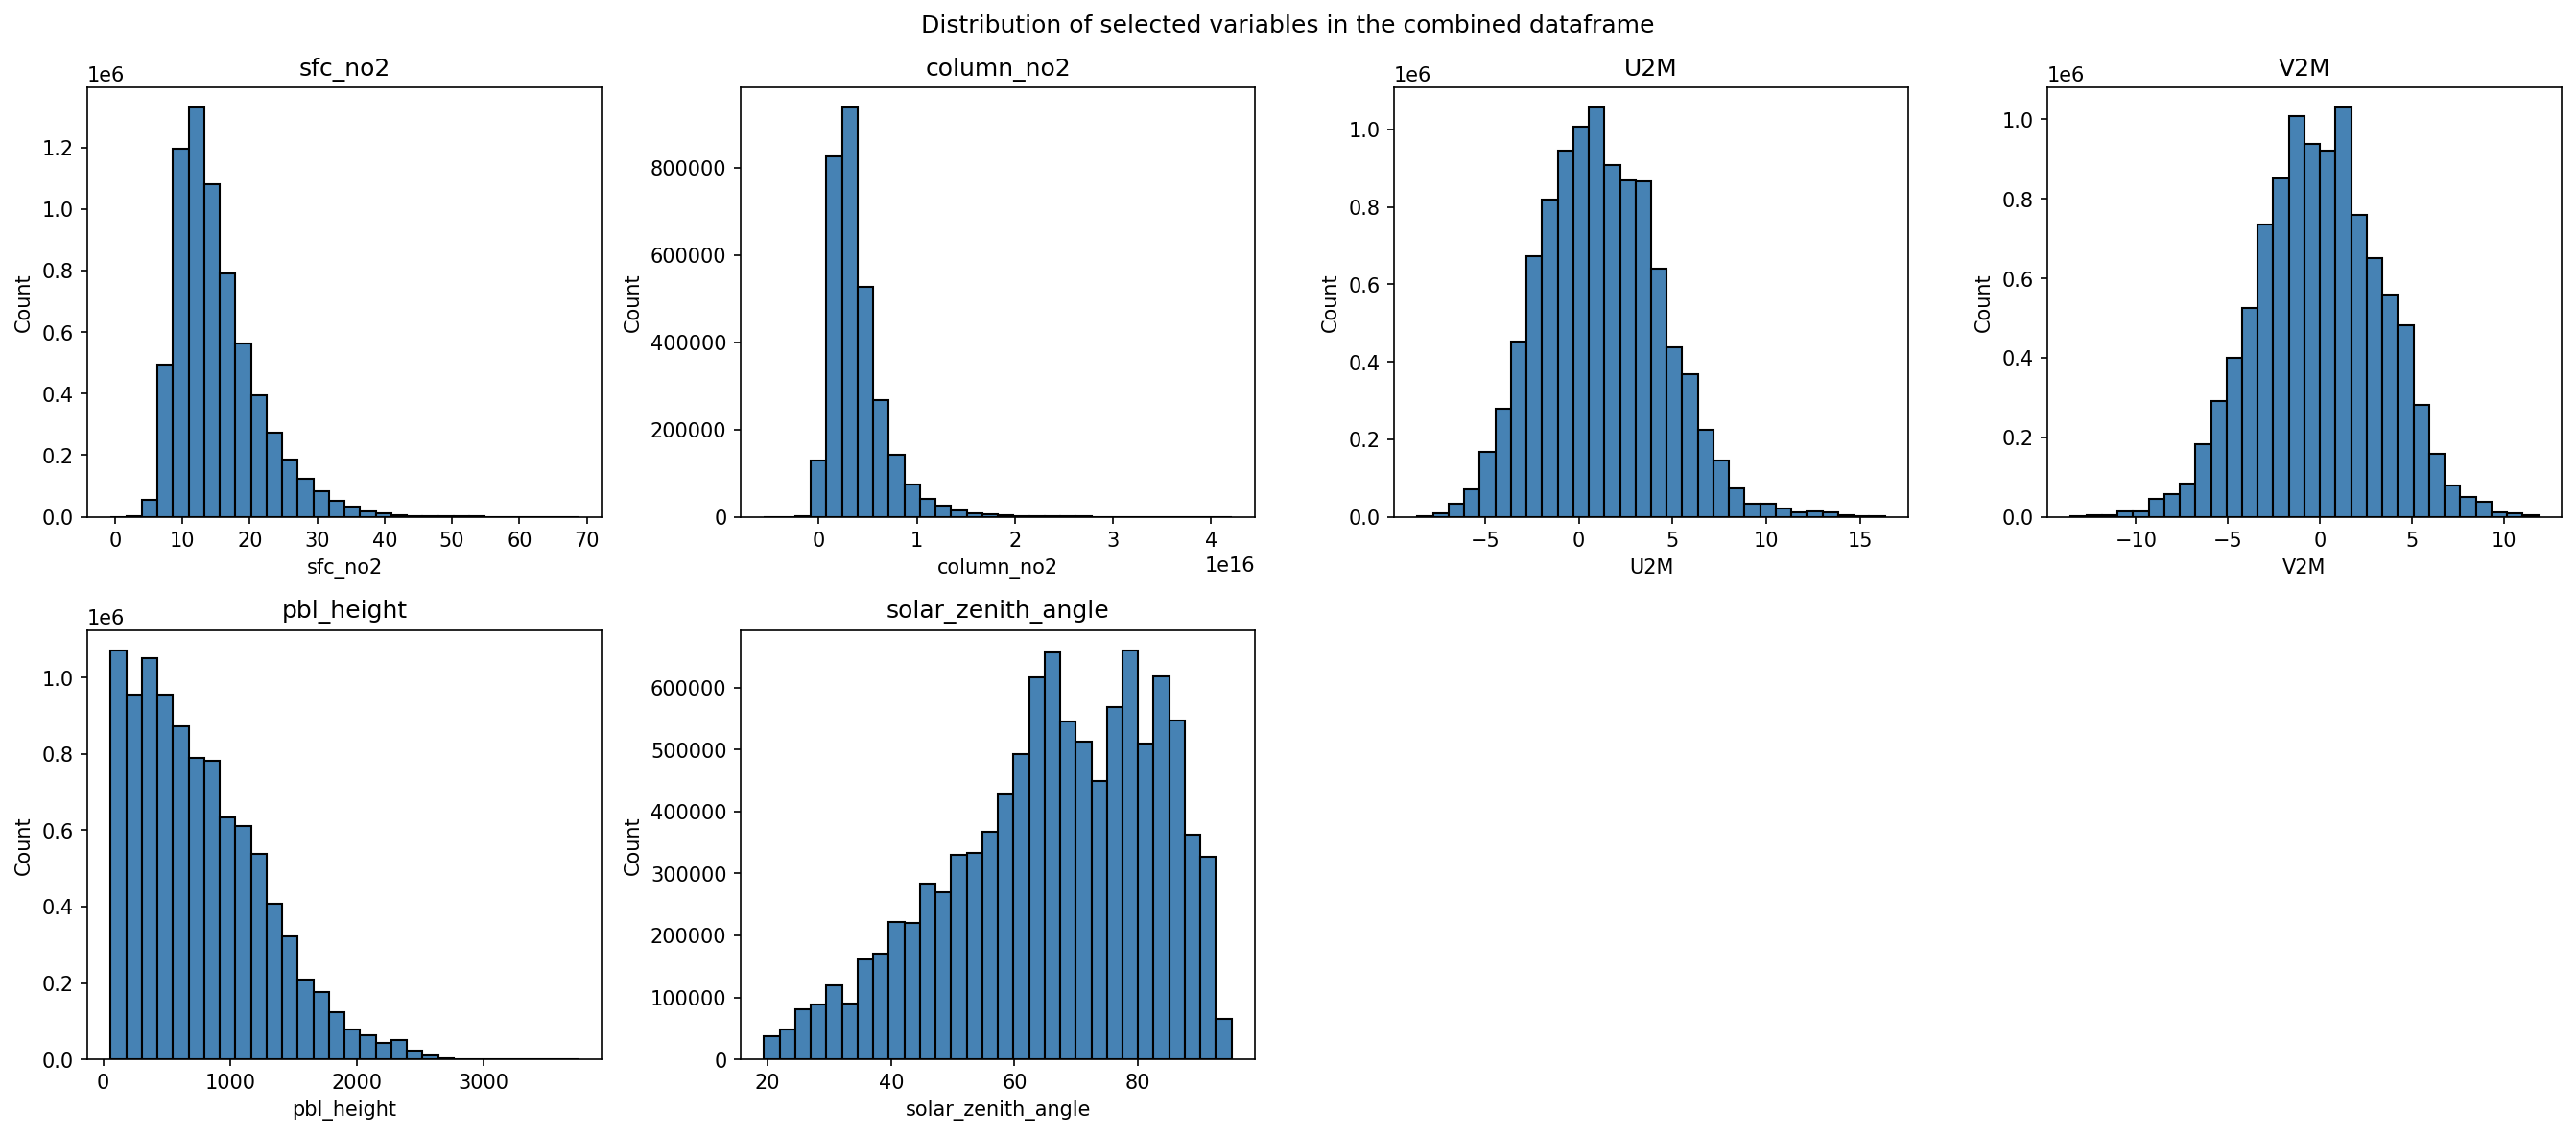

In [10]:
# combined['sfc_no2'] = combined['no2ConcIndividual.value']

plot_vars = [
    'sfc_no2',
    'column_no2',
    'U2M',
    'V2M',
    'pbl_height',
    'solar_zenith_angle'
]

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8))
axes = axes.flatten()

for ax, var in zip(axes, plot_vars):
    data = combined[var].dropna()
    if data.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(var)
        continue

    ax.hist(data, bins=30, color='steelblue', edgecolor='black')
    ax.set_title(var)
    ax.set_xlabel(var)
    ax.set_ylabel('Count')

# Hide any unused subplot
for ax in axes[len(plot_vars):]:
    ax.axis('off')

fig.suptitle('Distribution of selected variables in the combined dataframe', fontsize=12)
fig.tight_layout()
plt.show()


In [3]:
combined = pd.read_csv("/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-unaggregated.csv")

combined['datetime'] = pd.to_datetime(combined['datetime'], errors='coerce')

combined.drop(columns=combined.columns[0], inplace=True)

combined

,year,month,week,doy,hour,datetime,latitude,longitude,column_no2,pbl_height,solar_zenith_angle,U2M,V2M,U10M,V10M,sfc_no2
0,2025,9,36,244,0,2025-09-01 00:00:05,41.71,-87.69,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.90
1,2025,9,36,244,0,2025-09-01 00:00:11,41.91,-87.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.16
2,2025,9,36,244,0,2025-09-01 00:00:21,41.67,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.46
3,2025,9,36,244,0,2025-09-01 00:00:28,41.93,-87.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.98
4,2025,9,36,244,0,2025-09-01 00:00:32,41.71,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18351365,2026,6,25,166,0,2026-06-15 00:02:10,41.97,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.08
18351366,2026,6,25,166,0,2026-06-15 00:02:12,41.89,-87.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.05
18351367,2026,6,25,166,0,2026-06-15 00:02:14,41.69,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.52
18351368,2026,6,25,166,0,2026-06-15 00:02:14,42.01,-87.69,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.71


In [4]:
tempo_na_mask = (
    combined.set_index('datetime')
    .groupby([pd.Grouper('datetime', freq='1h'), 'latitude', 'longitude'])
    .agg(
        col_no2_mean=('column_no2', 'mean'),
        hour=('hour', 'first'),
        doy=('doy', 'first'),
        week=('week','first'),
        month=('month', 'first'),
        year=('year', 'first')
    )
    .reset_index()
    .drop(['datetime'], axis=1)
)

tempo_na_mask['rm_if_true'] = False
tempo_na_mask.loc[tempo_na_mask['col_no2_mean'].isna(), 'rm_if_true'] = True

combined_drop = combined.merge(tempo_na_mask, how="outer", on=['year','month','week','doy','hour','latitude','longitude'])

combined_drop['sfc_no2'] = combined_drop['sfc_no2'].mask(combined_drop['rm_if_true'])

# combined_drop.loc[~combined_drop['rm_if_true'], 'sfc_no2'] = np.nan
# combined_drop = combined_drop.loc[combined_drop['rm_if_true']==False].reset_index().drop('index',axis=1)
# combined_drop.to_csv('/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-aggregated-tempo-nan-filter.csv')

savepath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-unaggregated-pixelmask.csv"
combined_drop.to_csv(savepath)



In [5]:

hourly_dat = (
    combined_drop.set_index('datetime')
    .groupby([pd.Grouper('datetime', freq='1h'), 'latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

save_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-hourly-timeseries.csv"
hourly_dat.to_csv(save_path)



In [6]:

hourly_dat = (
    combined_drop.set_index('hour')
    .groupby(['hour', 'latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

save_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-diurnal-aggregation.csv"
hourly_dat.to_csv(save_path)


In [7]:
season_map = {
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Fall',
    10: 'Fall',
    11: 'Fall',
}
combined_drop['season'] = combined_drop['month'].map(season_map)

hourly_dat = (
    combined_drop.set_index(['hour', 'season'])
    .groupby(['hour', 'season', 'latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

save_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-seasonal-diurnal-aggregation.csv"
hourly_dat.to_csv(save_path)

In [8]:
hourly_dat = (
    combined_drop.set_index(['hour', 'month'])
    .groupby(['hour', 'month', 'latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

save_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-monthly-diurnal-aggregation.csv"
hourly_dat.to_csv(save_path)

In [9]:

hourly_dat = (
    combined_drop.set_index(['week'])
    .groupby(['week','latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

save_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-weekly-aggregation.csv"
hourly_dat.to_csv(save_path)

In [10]:

hourly_dat = (
    combined_drop.set_index(['month'])
    .groupby(['month','latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

save_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-monthly-aggregation.csv"
hourly_dat.to_csv(save_path)

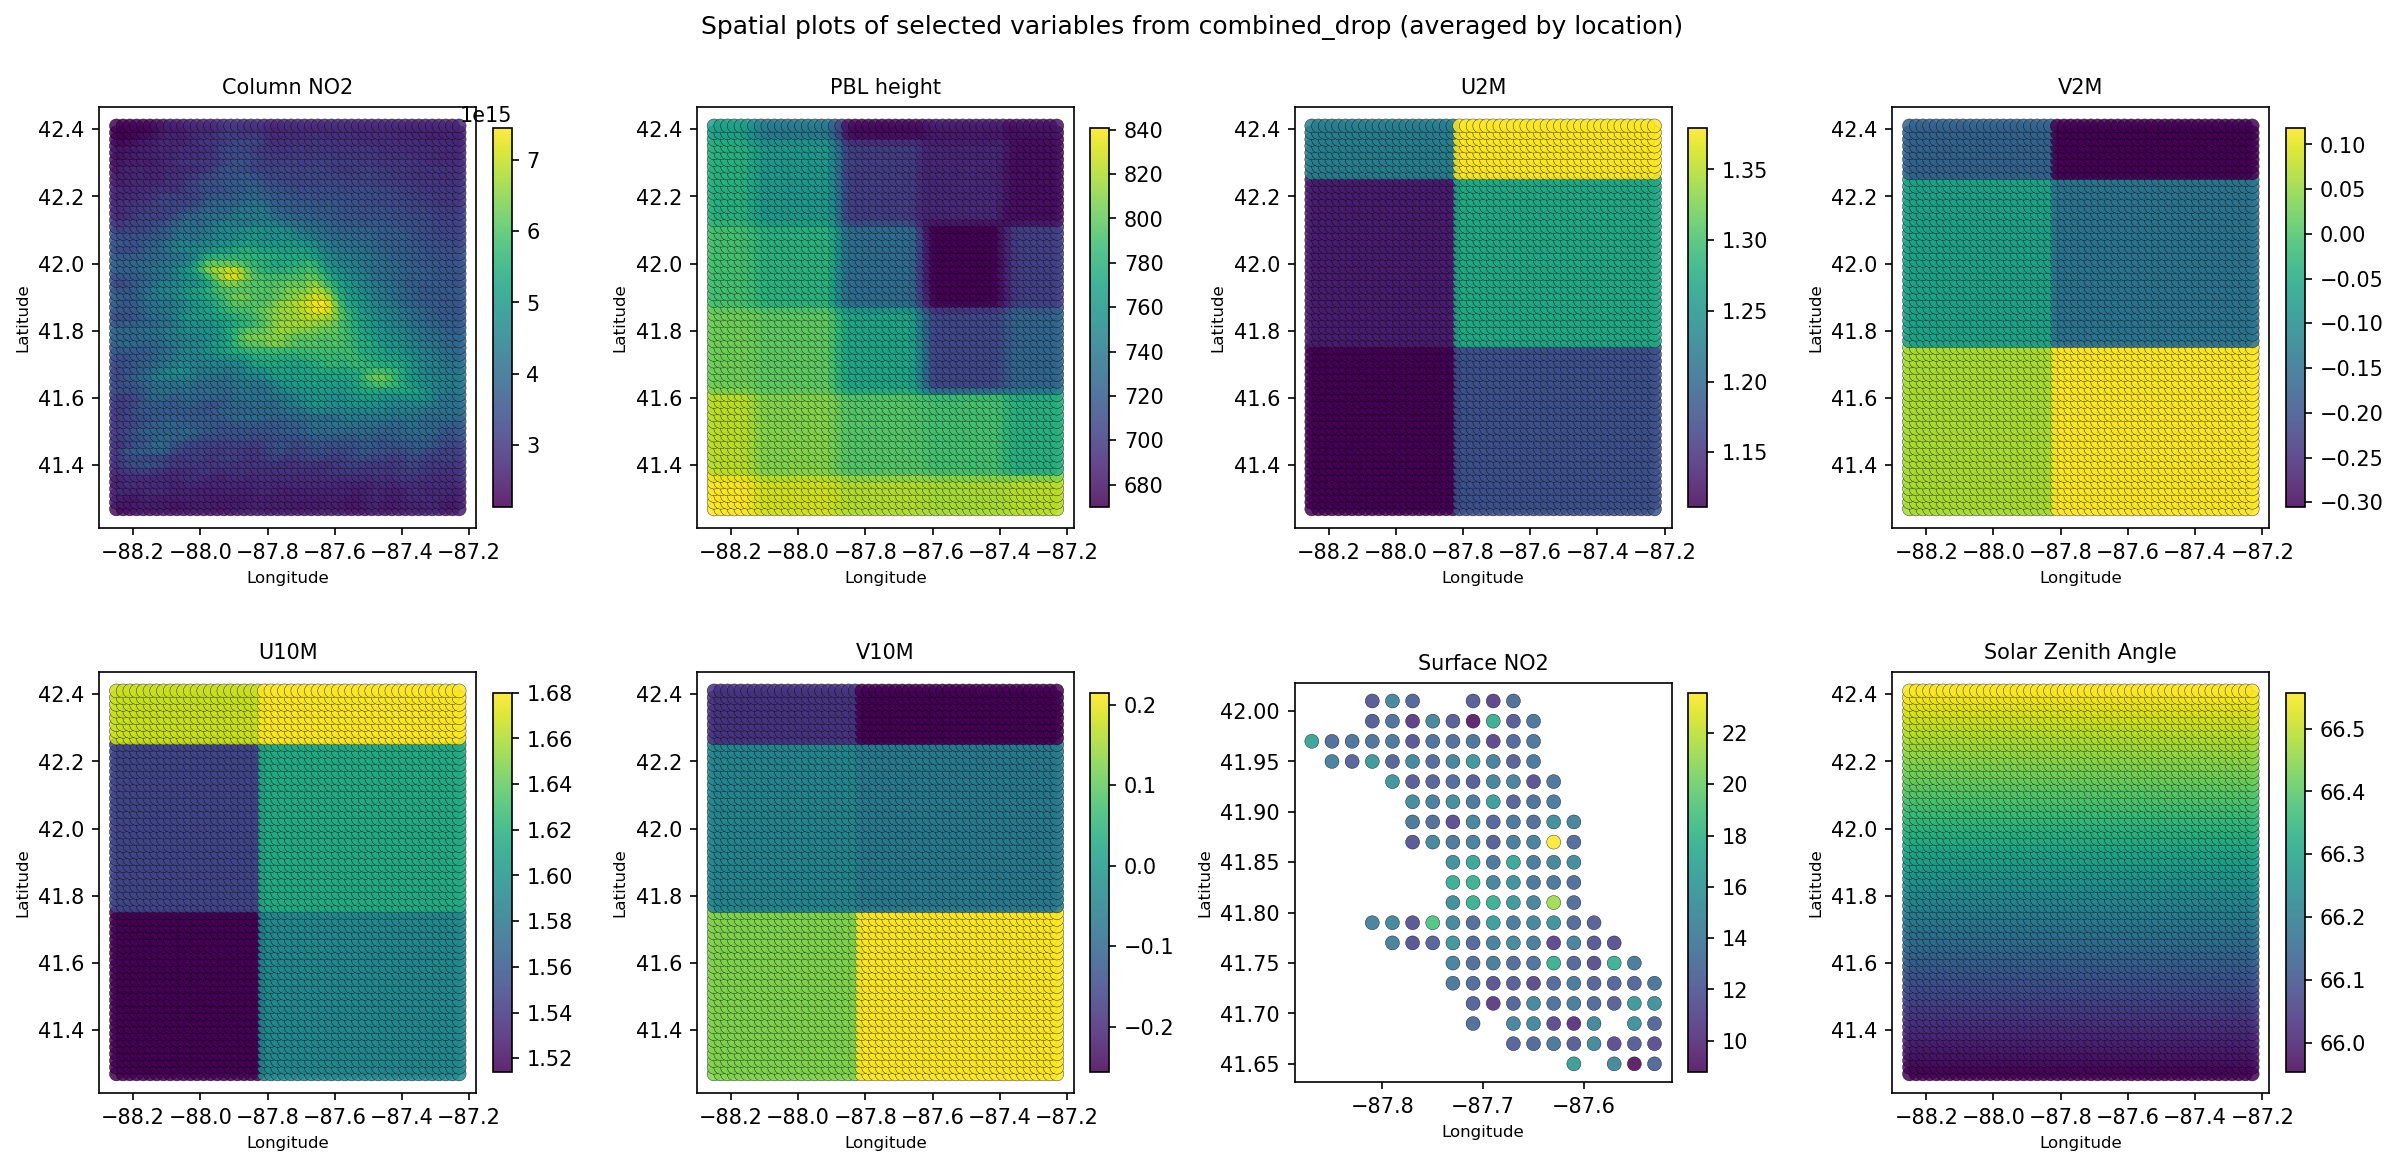

In [12]:
import matplotlib.pyplot as plt

plot_vars = [
    ("column_no2", "Column NO2"),
    ("pbl_height", "PBL height"),
    ("U2M", "U2M"),
    ("V2M", "V2M"),
    ("U10M", "U10M"),
    ("V10M", "V10M"),
    ("sfc_no2", "Surface NO2"),
    ('solar_zenith_angle', "Solar Zenith Angle")
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8), squeeze=False)
axes = axes.ravel()

for ax, (var, label) in zip(axes, plot_vars):
    spatial = (
        combined_drop[["longitude", "latitude", var]]
        .dropna()
        .groupby(["latitude", "longitude"], as_index=False)[var]
        .mean()
    )

    if spatial.empty:
        ax.text(0.5, 0.5, f"No data for {var}", ha="center", va="center")
        ax.set_title(label)
        continue

    sc = ax.scatter(
        spatial["longitude"],
        spatial["latitude"],
        c=spatial[var],
        s=45,
        cmap="viridis",
        alpha=0.85,
        edgecolor="k",
        linewidth=0.2,
    )
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Longitude", fontsize=8)
    ax.set_ylabel("Latitude", fontsize=8)
    ax.set_aspect("equal", adjustable="box")
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

for ax in axes[len(plot_vars):]:
    ax.axis("off")

fig.suptitle("Spatial plots of selected variables from combined_drop (averaged by location)", fontsize=12)
fig.tight_layout()
plt.show()


# CHECKING


In [ ]:
datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"

hourly = pd.read_csv(datapath+"fulldat-hourly-aggregation.csv")
hourly['datetime'] = pd.to_datetime(hourly['datetime'], errors='coerce')
hourly['hour'] = hourly['datetime'].dt.hour


diurnal = pd.read_csv(datapath+"fulldat-diurnal-aggregation.csv")
weekly = pd.read_csv(datapath+"fulldat-weekly-aggregation.csv")
monthly_diurnal = pd.read_csv(datapath+"fulldat-monthly-diurnal-aggregation.csv")
seasonal_diurnal = pd.read_csv(datapath+"fulldat-seasonal-diurnal-aggregation.csv")
monthly = pd.read_csv(datapath+"fulldat-monthly-aggregation.csv")



In [5]:

diurnal_xr = diurnal.set_index(['hour','latitude','longitude']).to_xarray()
# weekly_xr
# weekly_diurnal_xr
# seasonal_diurnal_xr
# monthly_xr

/tmp/ipykernel_101986/3480751943.py:229: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  o_figure.show()


((<Figure size 960x720 with 2 Axes>,
  <GeoAxes: xlabel='longitude', ylabel='latitude'>,
  <cartopy.mpl.geocollection.GeoQuadMesh at 0x7fa448a02490>),)

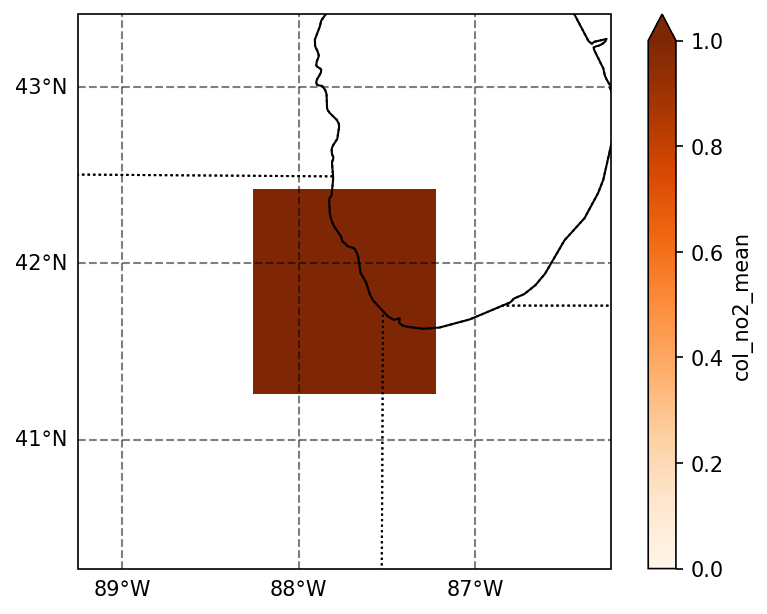

In [22]:
n_lat_min, n_lat_max, n_lon_min, n_lon_max = get_corners(diurnal_xr)

spatial_mean = diurnal_xr['col_no2_mean'].mean(dim='hour')

F_plot_map(a_data_plot = spatial_mean,
           n_lat_min=n_lat_min,
           n_lat_max=n_lat_max,
           n_lon_min=n_lon_min,
           n_lon_max=n_lon_max),
        #    Colorbar_Label = 'PM$_{2.5}$ [µg/m$^{3}$])
        #    Plot_Title = f'SatPM\n(Average {t_start} to {t_end})'
         #   Colorbar_Limits=[0,40])

In [13]:
def plotboxes(dataset, timeagg):

    hour_dat = dataset[[timeagg]].drop_duplicates().sort_values(timeagg).reset_index(drop=True)
    hours = [int(hour) for hour in hour_dat[timeagg].to_list()]

    fig, ax = plt.subplots(figsize=(12, 5))

    # hours = [int(hour) for hour in tempo_vals['hour'].to_list()]
    actual_by_hour = [dataset.loc[dataset[timeagg] == hour, 'col_no2_mean'].dropna() for hour in hours]
    positions_actual = [hour for hour in hours]


    ax.boxplot(
        actual_by_hour,
        positions=positions_actual,
        widths=0.3,
        patch_artist=True,
        boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
        medianprops=dict(color='navy'),
        whiskerprops=dict(color='navy'),
        capprops=dict(color='navy'),
    )

    ax.set_xticks(hours)
    ax.set_xticklabels(hours)
    ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
    ax.set_xlabel(timeagg)
    ax.set_ylabel('NO$_2$ (molecules m$^-2$)')
    ax.set_title('TEMPO troposphere column retrievals')
    ax.grid(True, axis='y', alpha=0.3)

    plt.tight_layout()

    # savefig("boxplot-tempo-mean-vals.png")
    plt.show()

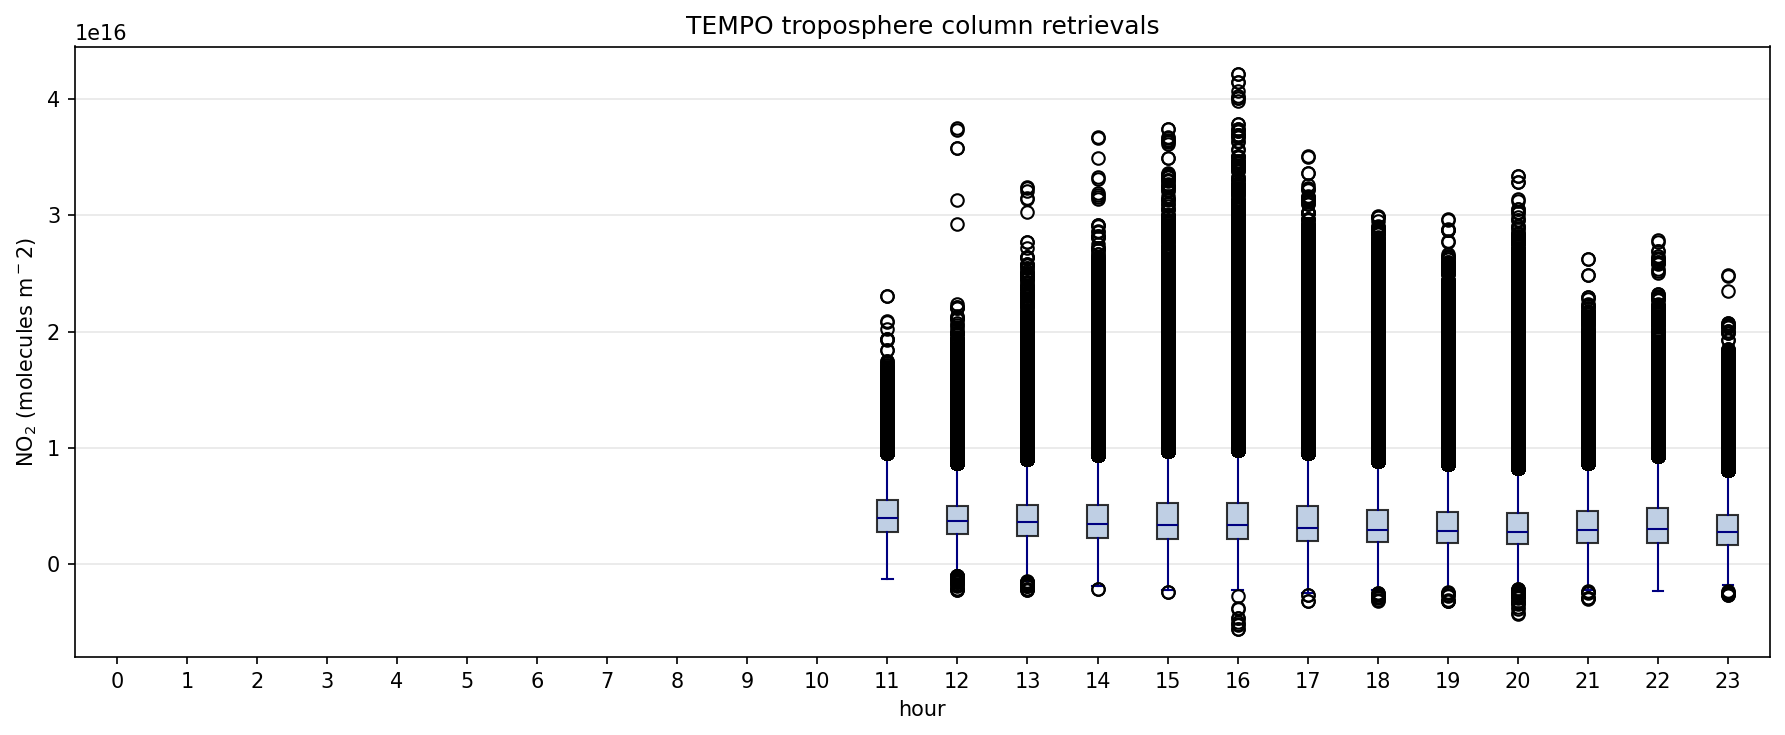

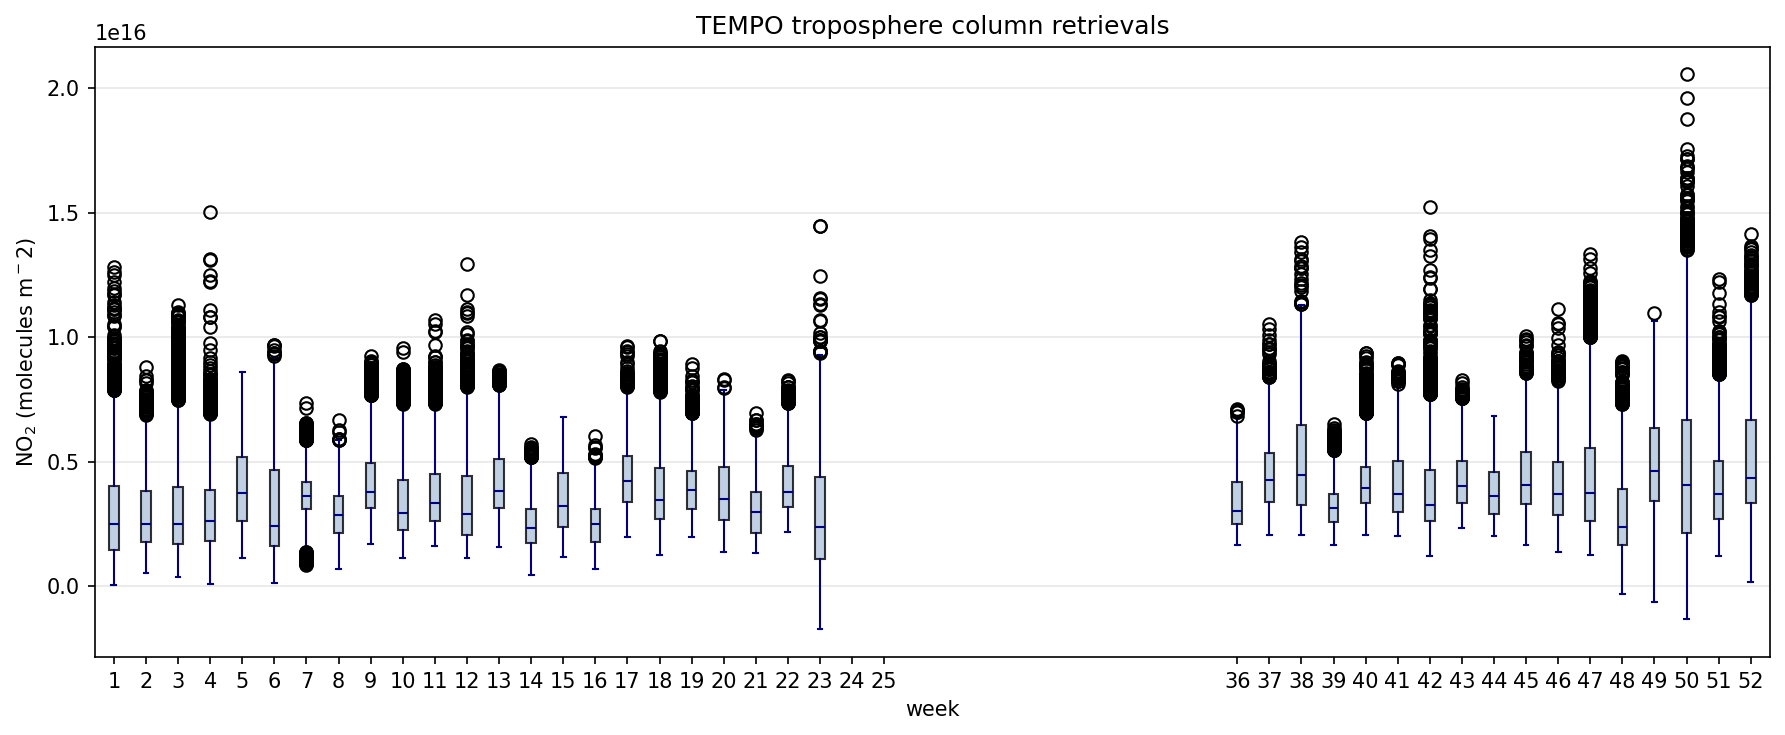

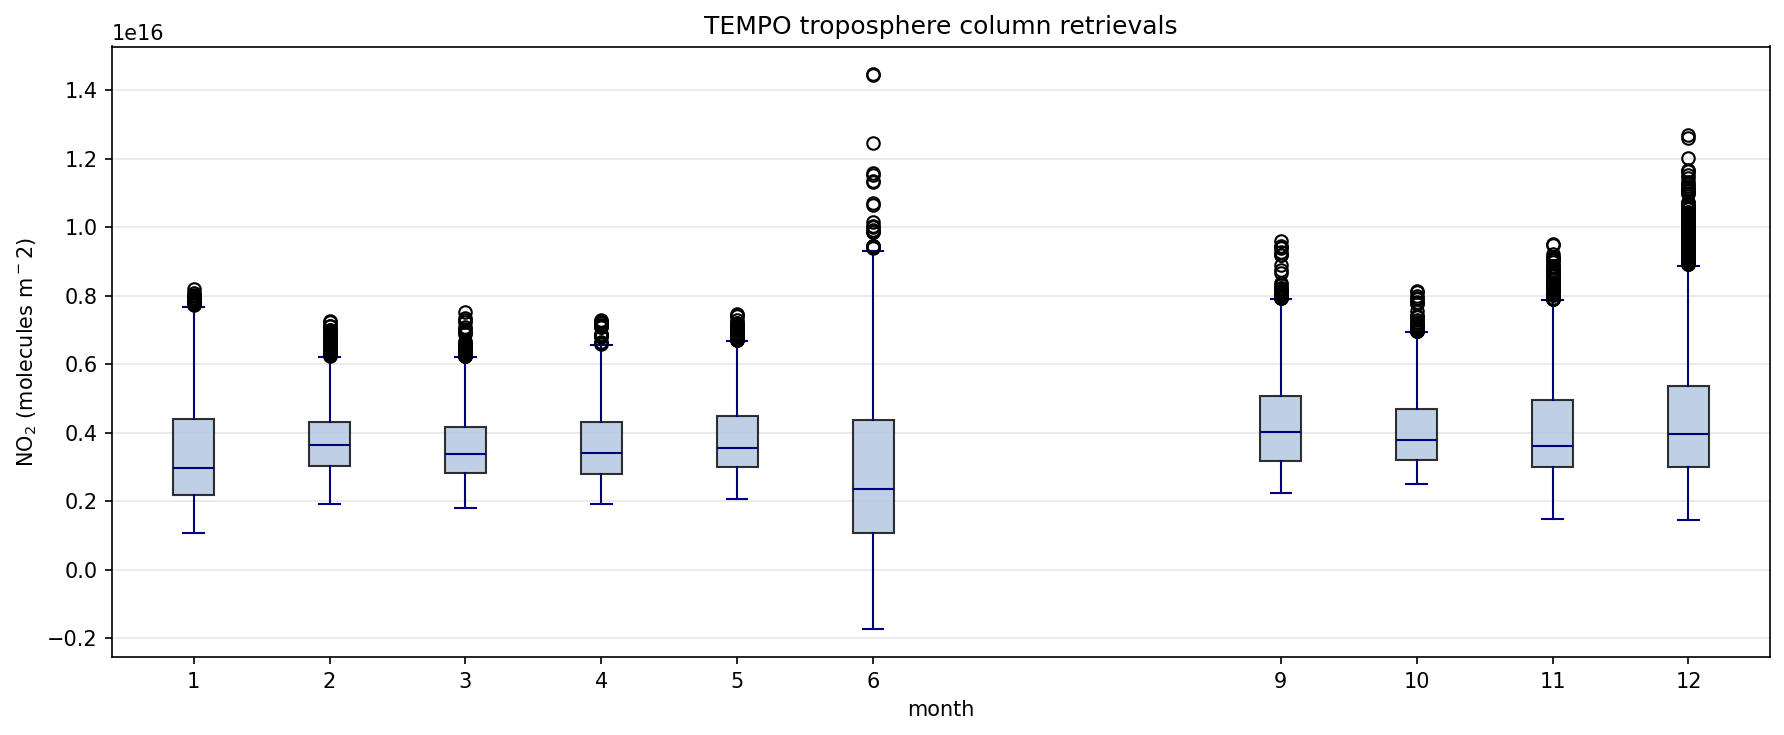

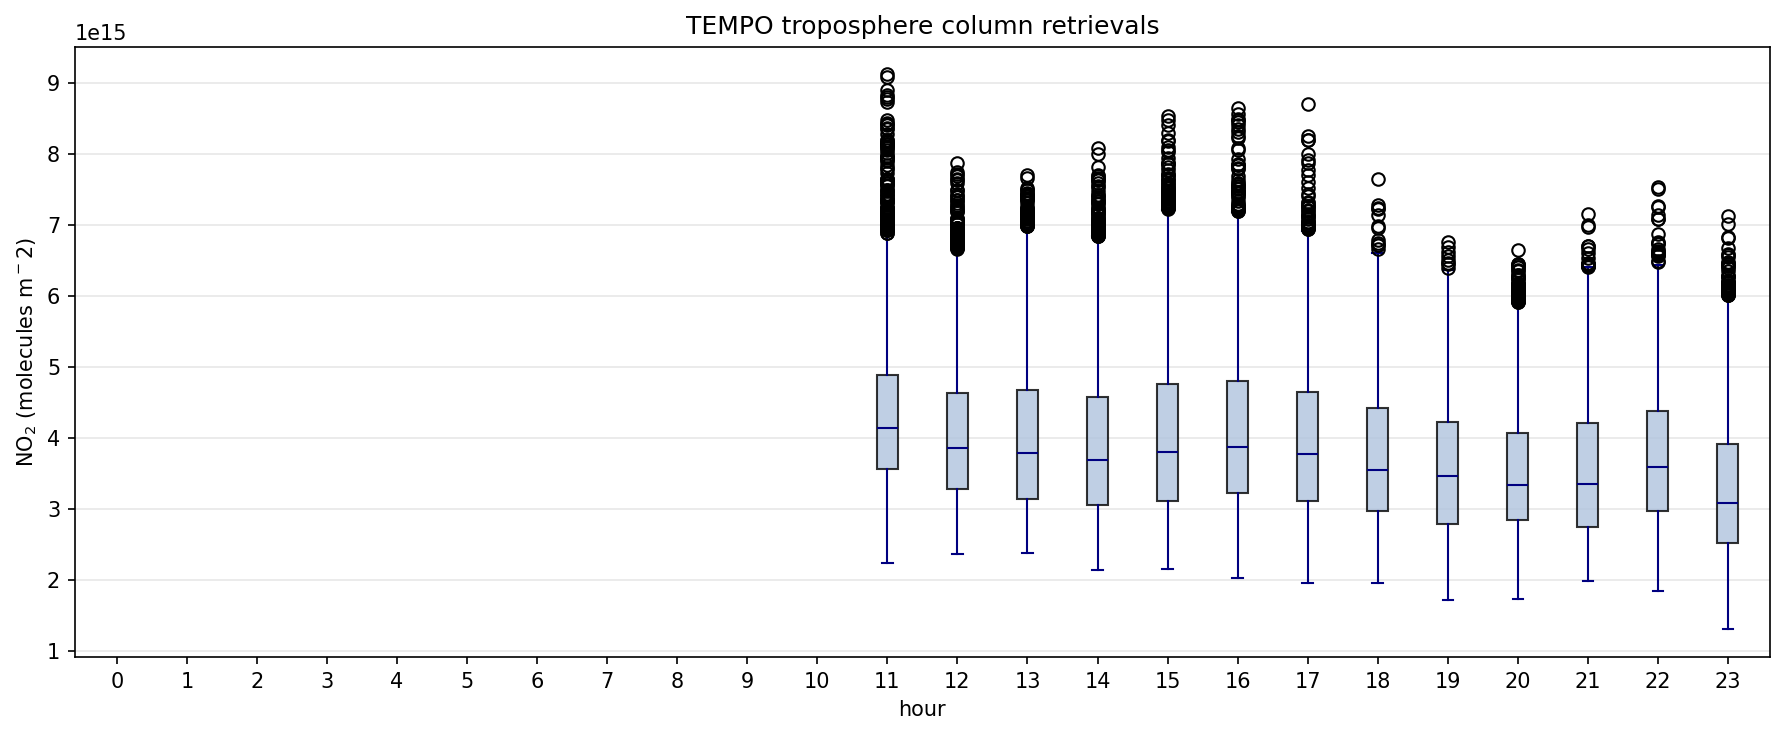

In [21]:
plotboxes(hourly, 'hour')
plotboxes(weekly,'week')
plotboxes(monthly,'month')
plotboxes(diurnal,'hour')